# RAGBench evaluation analysis

Loads every saved run under `artifacts/experiments/runs/` and compares the
configurations the experiments were run under. Nothing here is hardcoded:
re-run the notebook after new `ragbench evaluate` / `ragbench experiment`
runs and the tables and plots update.

A run file holds one record per evaluation case: the retrieved chunks, the
answer, the citations and the per-case metrics. See `docs/EXPERIMENTS.md`
for the metric definitions and the conclusions drawn from these numbers.

In [1]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "pyproject.toml").is_file():
    root = root.parent

RUNS_DIR = root / "artifacts" / "experiments" / "runs"
assert RUNS_DIR.is_dir(), f"no runs directory at {RUNS_DIR}; run 'ragbench evaluate' first"

from ragbench.evaluation.runner import read_run_file
from ragbench.evaluation.metrics import RetrievalMetrics, GenerationMetrics, OperationalMetrics

rows = []
for run_file in sorted(RUNS_DIR.glob("*.json")):
    summary, records = read_run_file(run_file)
    retrieval = RetrievalMetrics(records).as_dict()
    generation = GenerationMetrics(records).as_dict()
    operational = OperationalMetrics(records).as_dict()
    rows.append({
        "run_id": summary.run_id,
        "spec": summary.config.spec,
        "top_k": summary.config.top_k,
        "llm_model": summary.config.llm_model,
        "embedding_model": summary.config.embedding_model,
        "dataset_version": summary.config.dataset_version,
        "started_at": summary.started_at,
        **{f"recall@{k}": v for k, v in retrieval["recall"].items()},
        **{f"mrr@{k}": v for k, v in retrieval["mrr"].items()},
        **generation,
        "errors": operational["errors"],
        "mean_retrieval_s": operational["mean_retrieval_seconds"],
        "mean_generation_s": operational["mean_generation_seconds"],
        "total_tokens": operational["total_tokens"],
    })

runs = pd.DataFrame(rows).sort_values(["spec", "top_k"]).reset_index(drop=True)
print(f"{len(runs)} runs loaded")
runs

10 runs loaded


,run_id,spec,top_k,llm_model,embedding_model,dataset_version,started_at,recall@3,recall@5,recall@8,...,citation_precision,citation_recall,invalid_reference_rate,faithfulness_mean,token_f1_mean,exact_match_rate,errors,mean_retrieval_s,mean_generation_s,total_tokens
0,20261116-132628-large-1200-k3,large-1200,3,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:26:28.803368+00:00,1.000000,1.000000,1.000000,...,0.702703,1.000000,0.0,0.884615,0.659129,0.0,0,1.925,4.457,118331
1,20261116-132940-large-1200-k5,large-1200,5,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:29:40.363243+00:00,1.000000,1.000000,1.000000,...,0.650000,1.000000,0.0,0.807692,0.603327,0.0,0,1.808,4.333,188627
2,20261116-133244-large-1200-k8,large-1200,8,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:32:44.717470+00:00,1.000000,1.000000,1.000000,...,0.641026,0.961538,0.0,0.788462,0.667542,0.0,0,0.717,4.075,294515
3,20261116-133508-medium-800-k3,medium-800,3,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:35:08.594358+00:00,1.000000,1.000000,1.000000,...,0.735294,0.961538,0.0,0.865385,0.702408,0.0,0,0.849,4.098,83492
4,20261116-125352-medium-800-k5,medium-800,5,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 12:53:52.314014+00:00,1.000000,1.000000,1.000000,...,0.764706,1.000000,0.0,0.884615,0.634074,0.0,0,0.678,4.598,65764
5,20261116-133737-medium-800-k5,medium-800,5,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:37:37.090306+00:00,1.000000,1.000000,1.000000,...,0.684211,1.000000,0.0,0.846154,0.702250,0.0,0,1.094,3.876,131775
6,20261116-134006-medium-800-k8,medium-800,8,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:40:06.279790+00:00,1.000000,1.000000,1.000000,...,0.625000,0.961538,0.0,0.884615,0.639214,0.0,0,0.713,4.125,202365
7,20261116-134231-small-500-k3,small-500,3,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:42:31.525241+00:00,0.961538,0.961538,0.961538,...,0.705882,0.923077,0.0,0.817308,0.672982,0.0,0,2.109,4.168,57691
8,20261116-134539-small-500-k5,small-500,5,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:45:39.882920+00:00,0.961538,0.961538,0.961538,...,0.625000,0.961538,0.0,0.846154,0.704313,0.0,0,0.656,3.767,88390
9,20261116-134752-small-500-k8,small-500,8,minimax-code-global/MiniMax-M3.1-Flash,nvidia/nemotron-3.5-embed-8b,1.0.0,2026-11-16 13:47:52.639022+00:00,0.960000,0.960000,1.000000,...,0.605263,0.920000,0.0,0.880000,0.635898,0.0,2,14.197,3.925,125088


## Retrieval performance

Recall@K is the share of answerable cases whose expected passage appears in
the top-K retrieved chunks; MRR@K adds credit for ranking it early. Both use
the manually verified dataset in `data/eval/dataset.json`.

In [2]:
retrieval_columns = [c for c in runs.columns if c.startswith(("recall@", "mrr@"))]
runs[["run_id", "spec", "top_k", *retrieval_columns]]

,run_id,spec,top_k,recall@3,recall@5,recall@8,mrr@3,mrr@5,mrr@8
0,20261116-132628-large-1200-k3,large-1200,3,1.000000,1.000000,1.000000,0.891026,0.891026,0.891026
1,20261116-132940-large-1200-k5,large-1200,5,1.000000,1.000000,1.000000,0.891026,0.891026,0.891026
2,20261116-133244-large-1200-k8,large-1200,8,1.000000,1.000000,1.000000,0.891026,0.891026,0.891026
3,20261116-133508-medium-800-k3,medium-800,3,1.000000,1.000000,1.000000,0.897436,0.897436,0.897436
4,20261116-125352-medium-800-k5,medium-800,5,1.000000,1.000000,1.000000,0.871795,0.871795,0.871795
5,20261116-133737-medium-800-k5,medium-800,5,1.000000,1.000000,1.000000,0.897436,0.897436,0.897436
6,20261116-134006-medium-800-k8,medium-800,8,1.000000,1.000000,1.000000,0.897436,0.897436,0.897436
7,20261116-134231-small-500-k3,small-500,3,0.961538,0.961538,0.961538,0.903846,0.903846,0.903846
8,20261116-134539-small-500-k5,small-500,5,0.961538,0.961538,0.961538,0.903846,0.903846,0.903846
9,20261116-134752-small-500-k8,small-500,8,0.960000,0.960000,1.000000,0.900000,0.900000,0.905714


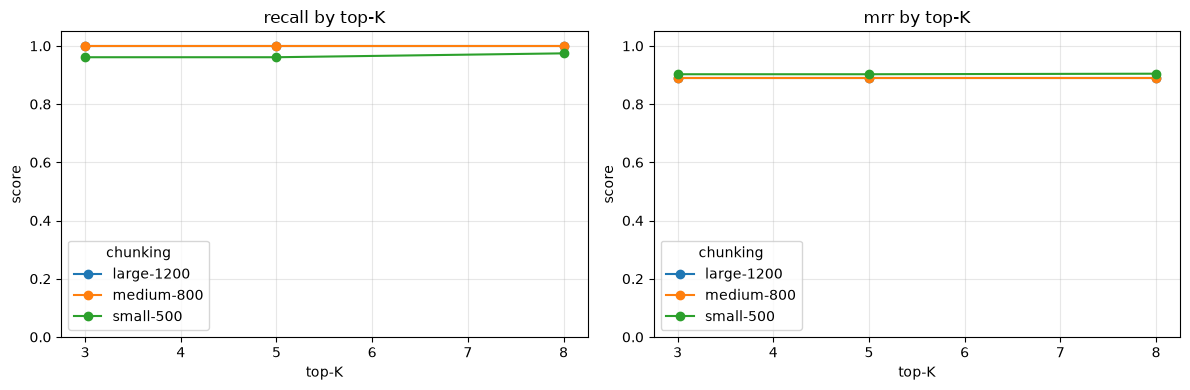

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, prefix in zip(axes, ("recall@", "mrr@")):
    columns = [c for c in runs.columns if c.startswith(prefix)]
    for spec, group in runs.groupby("spec"):
        group = group.sort_values("top_k").drop_duplicates("top_k")
        ks = sorted(set(group["top_k"]) | {3, 5, 8})
        means = group.set_index("top_k")[columns].mean(axis=0)
        axis.plot(ks, [means.get(f"{prefix}{k}", None) for k in ks], marker="o", label=spec)
    axis.set_title(f"{prefix.rstrip('@')} by top-K")
    axis.set_xlabel("top-K")
    axis.set_ylabel("score")
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.3)
    axis.legend(title="chunking")
fig.tight_layout()
fig.savefig(root / "artifacts" / "reports" / "retrieval_by_topk.png", dpi=150)
plt.show()

## Chunk size comparison

At a fixed top-K, how does the chunking configuration change retrieval and
generation quality? Smaller chunks fragment passages but rank precisely;
larger chunks hold whole passages but dilute the embedding.

In [4]:
DEFAULT_K = 5
at_k = runs[runs["top_k"] == DEFAULT_K].set_index("spec")
comparison_columns = [c for c in runs.columns if c.startswith(("recall@", "mrr@"))] + [
    "citation_precision", "citation_recall", "faithfulness_mean", "token_f1_mean",
    "abstention_rate_unanswerable",
]
present = [c for c in comparison_columns if c in at_k.columns]
at_k[present]

,recall@3,recall@5,recall@8,mrr@3,mrr@5,mrr@8,citation_precision,citation_recall,faithfulness_mean,token_f1_mean,abstention_rate_unanswerable
spec,,,,,,,,,,,
large-1200,1.000000,1.000000,1.000000,0.891026,0.891026,0.891026,0.650000,1.000000,0.807692,0.603327,1.0
medium-800,1.000000,1.000000,1.000000,0.871795,0.871795,0.871795,0.764706,1.000000,0.884615,0.634074,1.0
medium-800,1.000000,1.000000,1.000000,0.897436,0.897436,0.897436,0.684211,1.000000,0.846154,0.702250,1.0
small-500,0.961538,0.961538,0.961538,0.903846,0.903846,0.903846,0.625000,0.961538,0.846154,0.704313,1.0


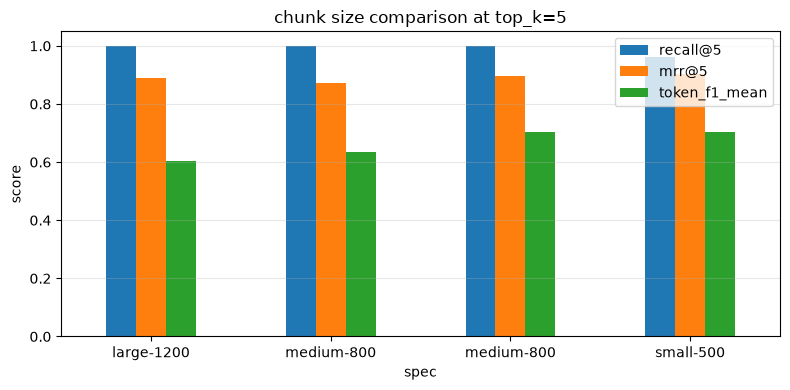

In [5]:
metric_columns = [c for c in ("recall@5", "mrr@5", "token_f1_mean") if c in at_k.columns]
if metric_columns:
    axis = at_k[metric_columns].plot(kind="bar", figsize=(8, 4), rot=0)
    axis.set_title(f"chunk size comparison at top_k={DEFAULT_K}")
    axis.set_ylabel("score")
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.3, axis="y")
    axis.figure.tight_layout()
    axis.figure.savefig(root / "artifacts" / "reports" / "chunk_size_comparison.png", dpi=150)
    plt.show()

## Top-K comparison

At a fixed chunk size, does retrieving more passages help recall, and what
does it cost in tokens and latency?

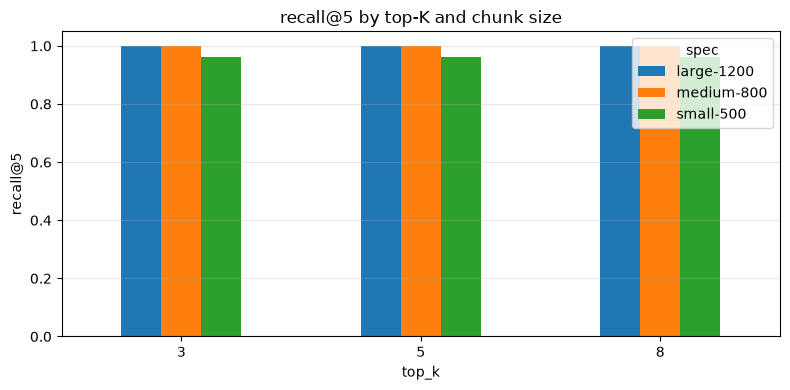

In [6]:
if len(runs["top_k"].unique()) > 1:
    axis = runs.pivot_table(index="top_k", columns="spec", values="recall@5", aggfunc="mean").plot(
        kind="bar", figsize=(8, 4), rot=0
    )
    axis.set_title("recall@5 by top-K and chunk size")
    axis.set_ylabel("recall@5")
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.3, axis="y")
    axis.figure.tight_layout()
    axis.figure.savefig(root / "artifacts" / "reports" / "topk_comparison.png", dpi=150)
    plt.show()
else:
    print("only one top-K in the saved runs; run 'ragbench experiment' for the grid")

## Latency and token usage

Operational cost per configuration. Generation latency dominates; retrieval
is one embedding call plus a local vector search.

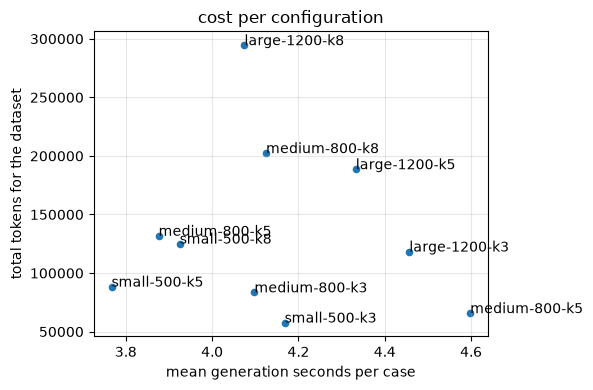

In [7]:
if len(runs) > 1 and len(runs["total_tokens"].dropna()) > 1:
    axis = runs.plot.scatter(x="mean_generation_s", y="total_tokens", figsize=(6, 4))
    for _, row in runs.iterrows():
        axis.annotate(f"{row['spec']}-k{row['top_k']}", (row["mean_generation_s"], row["total_tokens"]))
    axis.set_title("cost per configuration")
    axis.set_xlabel("mean generation seconds per case")
    axis.set_ylabel("total tokens for the dataset")
    axis.grid(alpha=0.3)
    axis.figure.tight_layout()
    axis.figure.savefig(root / "artifacts" / "reports" / "cost_per_configuration.png", dpi=150)
    plt.show()
else:
    runs[["run_id", "mean_retrieval_s", "mean_generation_s", "total_tokens"]]

## Per-case errors and abstentions

Every number above is recomputable from the records. The cells below surface
the cases a reviewer should read by hand: failed cases, abstentions on
answerable questions, and answers that were given on unanswerable ones.

In [8]:
problem_rows = []
for run_file in sorted(RUNS_DIR.glob("*.json")):
    summary, records = read_run_file(run_file)
    for record in records:
        if record.error:
            problem_rows.append({"run_id": summary.run_id, "case_id": record.case_id, "problem": f"error: {record.error}"})
        elif record.answerable and record.abstained:
            problem_rows.append({"run_id": summary.run_id, "case_id": record.case_id, "problem": "abstained on an answerable question"})
        elif not record.answerable and not record.abstained:
            problem_rows.append({"run_id": summary.run_id, "case_id": record.case_id, "problem": "answered an unanswerable question"})

pd.DataFrame(problem_rows, columns=["run_id", "case_id", "problem"]) if problem_rows else print("no problem cases in the saved runs")

,run_id,case_id,problem
0,20261116-134752-small-500-k8,q26,error: embedding endpoint failed after 5 attem...
1,20261116-134752-small-500-k8,u01,error: embedding endpoint failed after 5 attem...


In [9]:
last_records = []
for run_file in sorted(RUNS_DIR.glob("*.json")):
    summary, records = read_run_file(run_file)
    abstained = [record.case_id for record in records if record.abstained]
    if abstained:
        last_records.append({"run_id": summary.run_id, "abstained_cases": ", ".join(abstained)})
pd.DataFrame(last_records, columns=["run_id", "abstained_cases"]) if last_records else print("no abstentions recorded")

,run_id,abstained_cases
0,20261116-125352-medium-800-k5,"u01, u02"
1,20261116-132628-large-1200-k3,"u01, u02, u03, u04"
2,20261116-132940-large-1200-k5,"u01, u02, u03, u04"
3,20261116-133244-large-1200-k8,"u01, u02, u03, u04"
4,20261116-133508-medium-800-k3,"u01, u02, u03, u04"
5,20261116-133737-medium-800-k5,"u01, u02, u03, u04"
6,20261116-134006-medium-800-k8,"u01, u02, u03, u04"
7,20261116-134231-small-500-k3,"u01, u02, u03, u04"
8,20261116-134539-small-500-k5,"u01, u02, u03, u04"
9,20261116-134752-small-500-k8,"u02, u03, u04"
